# Bear vs background, step by step

A re-run of the bear-vs-background test (`background_test.ipynb`) with a check after every step, so each step can be verified before the next one.

**Question:** does the frozen MegaDescriptor recognize each bear from the bear itself, or from the enclosure behind it?

**Rules:** validation videos are the queries and training videos are the gallery. **The test split is never used.**

| Step | What | Status |
|---|---|---|
| 1 | Pick 5 frames per video | this notebook |
| 2 | Find the bear in each frame (Mask R-CNN masks) and review every mask by eye | this notebook |
| 3 | Decide which frames are usable | after the mask review |
| 4 | Make the edited images | |
| 5 | Embeddings (check: original = the baseline's saved embeddings) | |
| 6 | Match and score (check: original = the 5-frame baseline) | |
| 7 | Controls, including a new "gray hole" control | |

## 0. Imports and setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo folder (the first folder up that has requirements.txt)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

from experiments import heatmaps
from experiments import background_test as bt
from experiments.zoo_analysis import load_names

## Step 1. Pick the frames

The baseline uses 20 frames per video. Finding the bear is slow on a CPU (12.5 hours for 6,080 frames), so this test uses 5 of them, evenly spread: positions 0, 4, 8, 12 and 16 of the 20.

**Checks:** 1,216 videos x 5 = 6,080 frames; every video has exactly 5; no test frames.

In [2]:
frames, embeddings = heatmaps.load_frames()
keep = bt.pick_frames(frames)
len(keep)

6080

In [3]:
keep["split"].value_counts()

split
train         5005
validation    1075
Name: count, dtype: int64

In [4]:
keep.groupby("sequence").size().value_counts()

5    1216
Name: count, dtype: int64

Frames per bear and split:

In [5]:
pd.crosstab(keep["identity"], keep["split"], margins=True)

split,train,validation,All
identity,,,
000,430,90,520
001,365,80,445
002,380,80,460
003,410,90,500
004,365,80,445
005,375,80,455
006,375,80,455
007,365,80,445
008,420,90,510


One video: its 20 frames (the baseline's) and the 5 picked for this test.

In [6]:
video = keep["sequence"].iloc[0]
all_20 = frames.loc[frames["sequence"] == video, "frame"].sort_values().tolist()
picked = keep.loc[keep["sequence"] == video, "frame"].tolist()
print("baseline's 20 frames:", all_20)
print("picked (positions 0, 4, 8, 12, 16):", picked)
assert picked == all_20[0:20:4]

baseline's 20 frames: [0, 5, 10, 15, 20, 26, 31, 36, 41, 46, 52, 57, 62, 67, 72, 78, 83, 88, 93, 99]
picked (positions 0, 4, 8, 12, 16): [0, 20, 41, 62, 83]


## Step 2. Find the bear in every frame (Mask R-CNN)

**Model:** torchvision's Mask R-CNN (`maskrcnn_resnet50_fpn_v2`), trained on COCO everyday photos. It has no "polar bear" class, and often calls a polar bear a sheep, dog or cat, so **every animal class counts**.

**The mask** of a frame is the union of all animals found with score >= 0.5 (if none reaches 0.5, the single best animal, and step 3 then throws the frame out). A second bear in the crop is included on purpose.

The masks were made once (12.5 hours on this laptop's CPU) and saved in `data/background_masks.npz`; they are reused here, so what is reviewed is exactly what the earlier results used.

In [7]:
masks, info = bt.segment_bears(keep, None, None)     # loads the saved masks (no model needed)
masks.shape

(6080, 128, 256)

Which animal Mask R-CNN thought it saw (its most confident animal in each frame):

In [8]:
info["label"].value_counts()

label
bear        3874
sheep        999
dog          481
cat          294
bird         160
elephant     111
none          98
cow           49
horse         13
zebra          1
Name: count, dtype: int64

How much of the frame each mask covers (%):

In [9]:
(info["coverage"] * 100).describe().round(1)

count    6080.0
mean       39.3
std        14.1
min         0.0
25%        29.0
50%        38.8
75%        49.7
max        90.2
Name: coverage, dtype: float64

Frames that step 3 will throw out (score below 0.5 or mask under 2% of the frame); they get a red border in the review sheets:

In [10]:
usable = bt.usable_frames(info)
pd.Series({"usable": int(usable.sum()), "thrown out": int((~usable).sum())})

usable        5775
thrown out     305
dtype: int64

### Review every mask by eye

Writes to `results/background/mask_review/` (gitignored):
- `bearXXX_pYY.jpg`: every frame of every video, one row per video, 20 videos per page.
- `check_thrown_out_pYY.jpg`, `check_large_mask_p01.jpg`, `check_small_mask_p01.jpg`: frames to check first (thrown out in step 3; mask over 70% of the frame; mask under 15%). The detector's score is not used as a reason: it is about the animal's name, not the outline.
- `masks.csv`: one row per frame with an empty `bad_mask` column; write `y` next to any bad mask.

**How to read a frame:** bright = the mask (what counts as bear), dimmed = background, orange line = the mask's edge. Very dark frames (mostly bear `008`) are brightened on the sheets so the mask can be judged, marked `*` in the caption; this is for viewing only, the test uses the original frames.

**A good mask** covers the whole bear (head and legs included), does not spill onto large parts of the background (rock, water, a tree trunk), and does not cover a toy or other object. A second bear inside the mask is expected.

In [11]:
pages, check_pages, risky = bt.mask_review_sheets(keep, masks, info, usable, load_names())
print(len(pages), "bear pages,", len(check_pages), "check-first pages:", check_pages)
risky["why"].value_counts()

68 bear pages, 5 check-first pages: ['check_thrown_out_p01.jpg', 'check_thrown_out_p02.jpg', 'check_thrown_out_p03.jpg', 'check_large_mask_p01.jpg', 'check_small_mask_p01.jpg']


why
thrown_out    305
large_mask     53
small_mask     38
Name: count, dtype: int64

Pages per bear:

In [12]:
pd.Series(pages).str[4:7].value_counts().sort_index()

000    6
001    5
002    5
003    5
004    5
005    5
006    5
007    5
008    6
009    5
010    6
011    5
012    5
Name: count, dtype: int64

Frames thrown out, per bear (step 3 uses this rule; a bear that loses many frames is a warning):

In [13]:
pd.DataFrame({"frames": keep["identity"].value_counts().sort_index(),
              "thrown_out": pd.Series(~usable, index=keep.index).groupby(keep["identity"]).sum()}).assign(
    thrown_out_pct=lambda d: (d["thrown_out"] / d["frames"] * 100).round(1))

,frames,thrown_out,thrown_out_pct
identity,,,
000,520,3,0.6
001,445,13,2.9
002,460,2,0.4
003,500,5,1.0
004,445,27,6.1
005,455,31,6.8
006,455,0,0.0
007,445,4,0.9
008,510,122,23.9


A small preview of the first thrown-out page (open the full-size files to review):

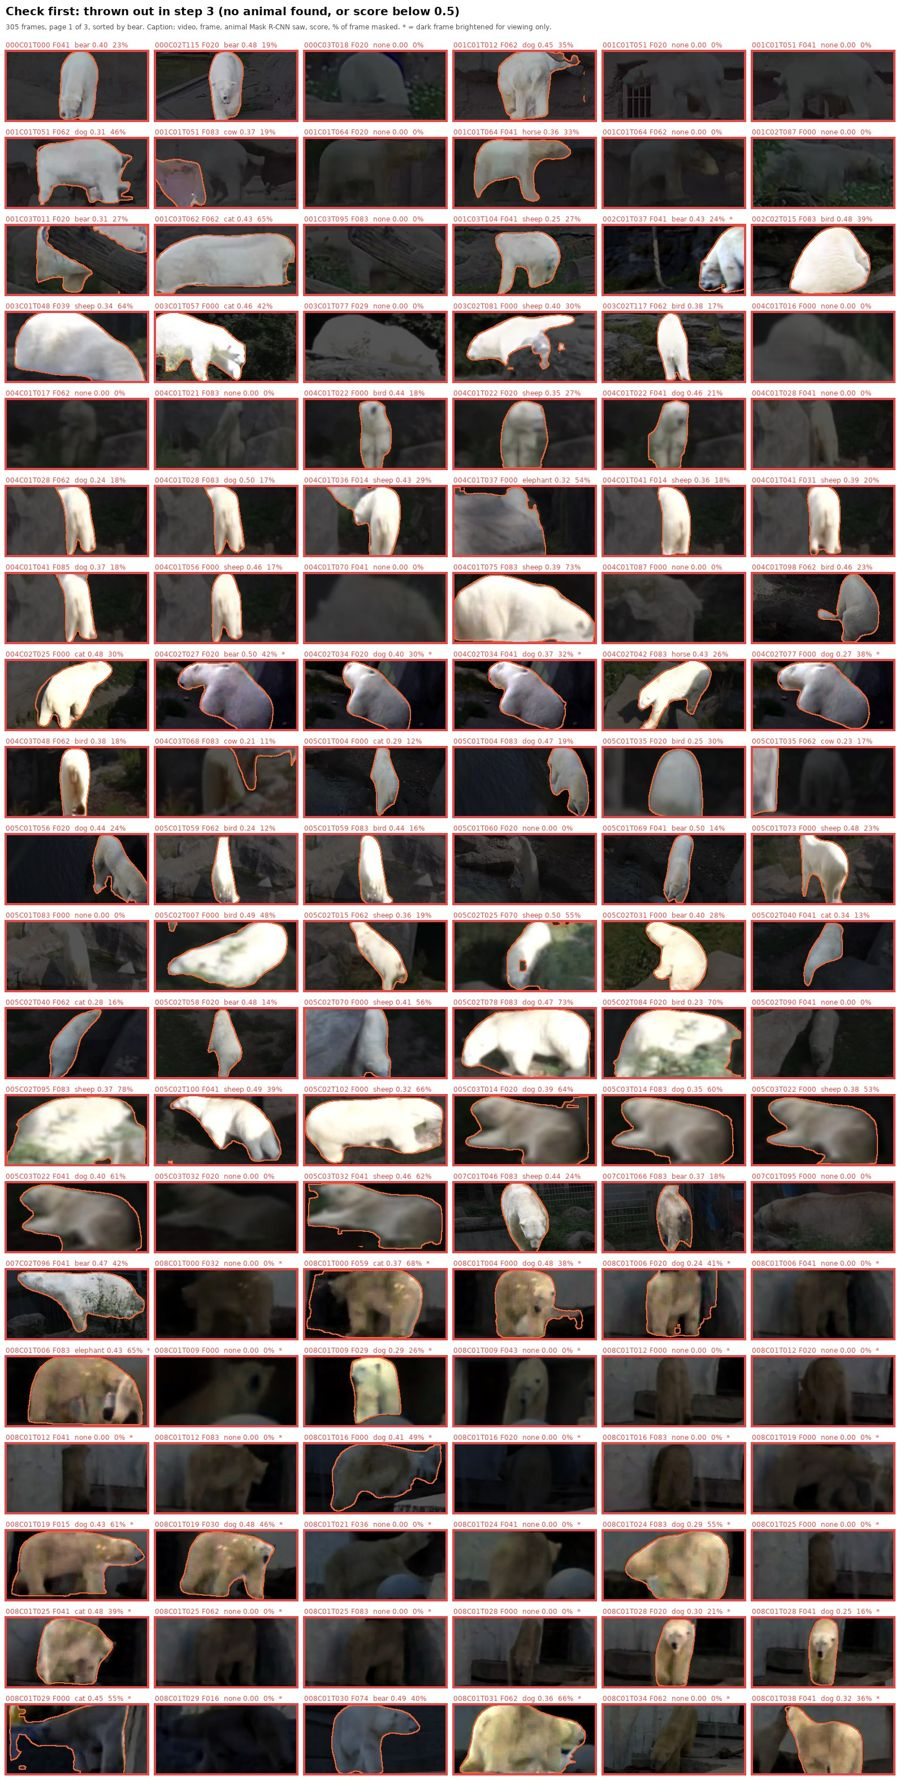

In [14]:
display(bt.review_preview("results/background/mask_review/check_thrown_out_p01.jpg"))

A small preview of one bear page:

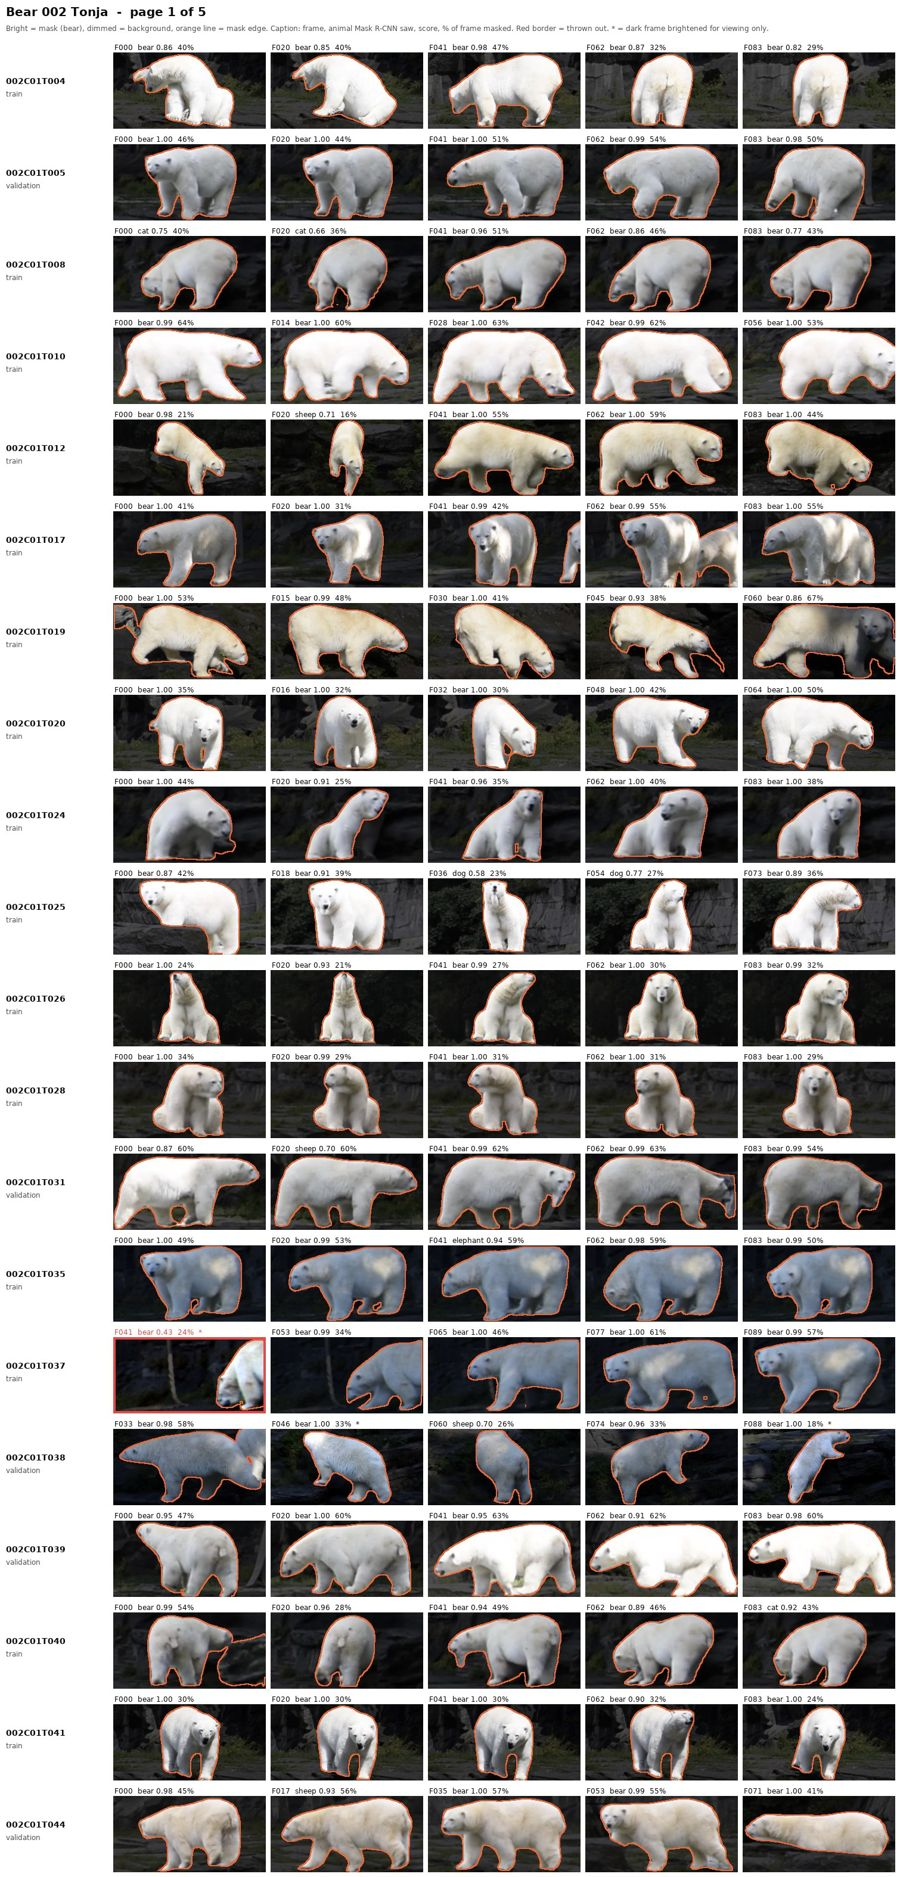

In [15]:
display(bt.review_preview("results/background/mask_review/bear002_p01.jpg"))

### After the review

Mark bad masks in `masks.csv` (`bad_mask` = `y`). Then: count them per bear; a few bad masks -> drop those frames; many for one bear -> look at why before trusting that bear's numbers. Then step 3.